<a href="https://colab.research.google.com/github/Emyfoton/Codigos_pregrado/blob/main/Diff_Electrones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd

# Funciones

In [ ]:
#FUNCIONES PARA CALCULAR LONGITUD DE ONDA
def broglie(u,err_u):
    #OJO: los U y err_U deben estar en V no kV
    h= 6.62607015e-34 #J s
    e=1.602176634e-19 # C
    m_e= 9.1093837139e-31 #kg
    lambd = h/np.sqrt(2*e*m_e*u)
    err_lambd = (lambd*err_u)/(2*u)
    return lambd,err_lambd

def bragg(dist,d,err_d):
    #OJO: los D deben estar en m no cm
    m=1
    L=0.135 #m
    theta=np.atan(d/(2*L))/2
    lambd =(2*dist/m) * np.sin(theta)
    err_lambd = (2*dist*L*err_d*np.cos(theta))/(m*(4*L**2 + d**2))
    return lambd,err_lambd


#FUNCIONES PARA EL AJUSTE DE D
def linear_function(X, a, b):
    return a * X + b

def ajuste(data):
    # Perform the curve fitting
    popt, pcov = curve_fit(linear_function, data["x"], data["y"],sigma=data["err_y"], absolute_sigma=True)

    # Get the slope and intercept
    slope = popt[0]
    intercept = popt[1]

    # Get the standard errors for the parameters
    slope_std_err = np.sqrt(pcov[0, 0])
    intercept_std_err = np.sqrt(pcov[1, 1])

    # Predict the Y values
    Y_pred = linear_function(data["x"], *popt)

    # Calculate residuals
    residuals = data["y"] - Y_pred


    #PARAMETROS ESTADISTICOS
    #r^2
    ss_res = np.sum(residuals ** 2)
    ss_tot = np.sum((data["y"] - np.mean(data["y"])) ** 2)
    r_squared = 1 - (ss_res / ss_tot)

    #Chi cuadrado reducido
    chi_cuadrado = np.sum((residuals / data["err_y"]) ** 2)
    grados_libertad = len(data["x"]) - 2
    chi_cuadrado_reducido = chi_cuadrado / grados_libertad

    print(f"Slope: {slope} ± {slope_std_err}")
    print(f"Intercept: {intercept} ± {intercept_std_err}")
    print(f"Residuals: {residuals}")
    print(f"R²: {r_squared}")
    print(f"Chi-cuadrado absoluto (X2): {chi_cuadrado}")
    print(f"Chi-cuadrado reducido (X2_nu): {chi_cuadrado_reducido}")

    return Y_pred,residuals,slope,slope_std_err,intercept,intercept_std_err

def graph_diameters(data1,data2,labels,save_graph=False):
    Y_pred1,residuals1,slope1,slope_std_err1,intercept1,intercept_std_err1 = ajuste(data1)
    Y_pred2,residuals2,slope2,slope_std_err2,intercept2,intercept_std_err2 = ajuste(data2)

    # Create a figure with two subplots
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), gridspec_kw={'height_ratios': [2, 1]})  # 2 rows, 1 column, width = 10 inches, height = 10 inches

    # Plot the regression line
    equation1 = f"${labels['y']} = ({slope1:.1f} \\pm {slope_std_err1:.1f}) \\cdot {labels['x']} + ({intercept1:.3f} \\pm {intercept_std_err1:.3f})$"
    ax1.errorbar(data1["x"], data1["y"],yerr=data1["err_y"],xerr= data1["err_x"],  fmt='o',color="cyan", label="Datos Diametro Interior")
    ax1.plot(data1["x"], Y_pred1, color="cyan", linewidth=2, label=equation1)

    equation2 = f"${labels['y']} = ({slope2:.1f} \\pm {slope_std_err2:.1f}) \\cdot {labels['x']} + ({intercept2:.3f} \\pm {intercept_std_err2:.3f})$"
    ax1.errorbar(data2["x"], data2["y"],yerr=data2["err_y"],xerr= data2["err_x"],  fmt='o',color="magenta", label="Datos Diametro Exterior")
    ax1.plot(data2["x"], Y_pred2, color="magenta", linewidth=2, label=equation2)

    ax1.set_xlabel(f"${labels["x"]}$")
    ax1.set_ylabel(f"${labels["y"]}$")
    ax1.legend(loc='lower right')
    ax1.set_title(labels["title"])
    ax1.grid()

    # Plot residuals
    ax2.scatter( data1["x"], residuals1, color='cyan', alpha=0.5, label='Residuales Diametro Interior')
    ax2.scatter( data2["x"], residuals2, color='magenta', alpha=0.5, label='Residuals Diametro Exterior')


    ax2.axhline(0, color='black', linewidth=1, linestyle='--')
    ax2.set_xlabel(f"${labels["x"]}$")
    ax2.set_ylabel('Unweighted residuals')
    ax2.legend(loc='lower right')
    ax2.grid()

    plt.tight_layout()

    if save_graph==True:
        # Save the figure as a PDF file
        plt.savefig(f"{labels['title']}.png", format='png')
    plt.show()


#FUNCIONES PARA HALLAR LOS DIAMETROS Y CTE DE PLANK
def distancia(pendiente,err_pend):
    h= 6.62607015e-34 #J s
    e=1.602176634e-19 # C
    m_e= 9.1093837139e-31 #kg
    L=0.135 #m
    dist=(2*L*h)/(pendiente*np.sqrt(2*e*m_e))
    err_dist = dist*err_pend/pendiente

    return dist, err_dist

def plank(pendiente,err_pend,dist):
    e=1.602176634e-19 # C
    m_e= 9.1093837139e-31 #kg
    L=0.135 #m

    cte= np.sqrt(2*e*m_e)/(2*L)
    plank= pendiente*dist*cte
    err_plank = plank*err_pend/pendiente

    return plank,err_plank

def incertidumbre_relativa(x,sigma_x):
    print(f"Incertidumbre relativa de {(sigma_x/x)*100}%")

def z_score(x_nom,x_exp,sigma):
    print(f"Z-score de {np.abs(x_nom-x_exp)/sigma}")


# Datos Emily

TABLA RESULTADOS
   V (kV)  D1 (cm)  D2 (cm)  λ_broglie (pm)  sigma_λ_broglie (pm)  \
0     1.6     4.44     6.92       30.660649              0.958145   
1     1.8     4.00     6.64       28.907137              0.802976   
2     2.0     3.90     6.42       27.423718              0.685593   
3     2.2     3.76     6.06       26.147489              0.594261   
4     2.4     3.22     6.04       25.034315              0.521548   
5     2.6     3.34     5.78       24.052192              0.462542   
6     2.8     3.22     5.32       23.177272              0.413880   
7     3.0     3.12     5.26       22.391372              0.373190   

   λ¹_bragg (pm)  sigma_λ¹_bragg (pm)  λ²_bragg (pm)  sigma_λ²_bragg (pm)  
0      34.677550             1.531137      30.779299             0.848233  
1      31.299461             1.539720      29.588481             0.852913  
2      30.529139             1.541558      28.648302             0.856487  
3      29.449169             1.544059      27.101504     

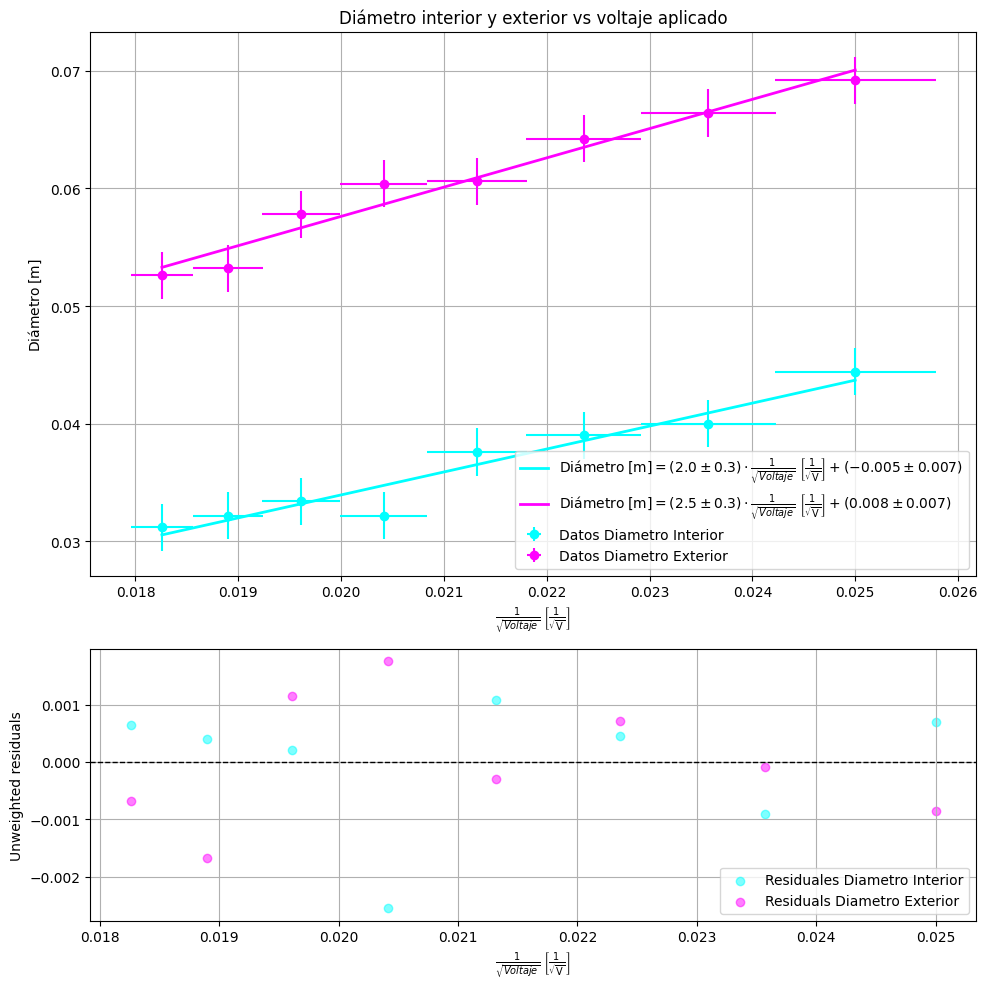

--------------------------------------------------------------------------- 


VALORES EXPERIMENTALES CTES
d1 = (165.56750531866217 +/- 16.556750531866214) pm
Incertidumbre relativa de 9.999999999999998%
Z-score de 2.8648432305630336


d2 = (132.4540042549297 +/- 10.59632034039438) pm
Incertidumbre relativa de 8.000000000000002%
Z-score de 0.8921969090430357


h = (8.524335371446329e-34 +/- 8.524335371446329e-35) Js
Incertidumbre relativa de 10.0%
Z-score de 2.226877684569852


h = (6.153129405445413e-34 +/- 4.92250352435633e-35) Js
Incertidumbre relativa de 8.0%
Z-score de 0.9607727901351353




In [ ]:
#datos Emily
U_data= np.array([1.2,1.4,1.6,1.8,2,2.2,2.4,2.6,2.8,3]) #kV
err_U_data=np.array([0.1]*10) #Incertidumbre +-0.1 kV

Dg_Err= np.array([3.14, 3.41, 3.46, 3.32, 3.21, 3.03, 3.02, 2.89, 2.66, 2.63]) #Radio grande medido cm
Dp_Err= np.array([2.73, 2.60, 2.22, 2, 1.95, 1.88, 1.61, 1.67, 1.61, 1.56]) #Radio pequeño medido cm
Dp_data = Dp_Err * 2 #Dado que cometimos el error de medir radios y no diametros, multiplicamos los datos x2

Dg_data = Dg_Err * 2
err_D_data= np.array([0.1*2]*10) #incertidumbre diametros +-0.1 cm


#DATOS FITLRADOS:
indices = [ 2, 3, 4, 5, 6, 7, 8, 9] #eliminamos datos 0 y 1
U = U_data[indices]
err_U = err_U_data[indices]

Dp = Dp_data[indices]
Dg = Dg_data[indices]
err_D = err_D_data[indices]



#---------------------------------------------------------------------------------------------------
#TABLA:
d1= 213e-12 #m
d2= 123e-12 #m
brog,err_brog = broglie(U*1000, err_U*1000) #m
brag1, err_brag1 = bragg(d1,Dp/100,err_D/100) #m
brag2, err_brag2 = bragg(d2,Dg/100,err_D/100) #m


tabla1 = {
    "V (kV)": U, #err +-0.1 kV
    "D1 (cm)": Dp, #err +-0.1 cm
    "D2 (cm)": Dg, #err +-0.1 cm
    "λ_broglie (pm)": brog * 1e12,
    "sigma_λ_broglie (pm)": err_brog * 1e12,
    "λ¹_bragg (pm)": brag1 * 1e12,
    "sigma_λ¹_bragg (pm)": err_brag1 * 1e12,
    "λ²_bragg (pm)": brag2 * 1e12,
    "sigma_λ²_bragg (pm)": err_brag2 * 1e12
}

df = pd.DataFrame(tabla1)
print("TABLA RESULTADOS")
print(df)
print("--------------------------------------------------------------------------- \n\n")



#---------------------------------------------------------------------------------------------------
#Grafica
x = 1/np.sqrt(U*1000) # unidades 1/sqrt(V)
err_x = (err_U*1000)/ (2*(U*1000)**1.5) # unidades 1/sqrt(V)
y1= Dp/100 #m
y2= Dg/100 #m
err_y= err_D/100 #m

data1 = {"x": x, "y": y1, "err_x": err_x, "err_y": err_y}
data2 = {"x": x, "y": y2, "err_x": err_x, "err_y": err_y}

labels = {
    "x": r"\frac{1}{\sqrt{Voltaje}} \; \left[ \frac{1}{\sqrt{\text{V}}} \right]",
    "y": r"\text{Diámetro} \; [\text{m}]",
    "title": 'Diámetro interior y exterior vs voltaje aplicado'}
print("DATOS GRAFICA")
graph_diameters(data1, data2, labels, save_graph=False)
print("--------------------------------------------------------------------------- \n\n")



#---------------------------------------------------------------------------------------------------
#Valores Constantes
pendiente_g= 2.5
err_pend_g = 0.2
pendiente_p= 2.0
err_pend_p = 0.2

dist1, err_dist1 = distancia(pendiente_p,err_pend_p)
dist2, err_dist2 = distancia(pendiente_g,err_pend_g)
cte_plank1, error_cte_plank1= plank(pendiente_p,err_pend_p,d1)
cte_plank2, error_cte_plank2= plank(pendiente_g,err_pend_g,d2)

print("VALORES EXPERIMENTALES CTES")
h= 6.62607015e-34 #J s
print(f"d1 = ({dist1*1e12} +/- {err_dist1*1e12}) pm")
incertidumbre_relativa(dist1*1e12,err_dist1*1e12)
z_score(213,dist1*1e12,err_dist1*1e12)
print("\n")

print(f"d2 = ({dist2*1e12} +/- {err_dist2*1e12}) pm")
incertidumbre_relativa(dist2*1e12,err_dist2*1e12)
z_score(123,dist2*1e12,err_dist2*1e12)
print("\n")
print(f"h = ({cte_plank1} +/- {error_cte_plank1}) Js")
incertidumbre_relativa(cte_plank1,error_cte_plank1)
z_score(h,cte_plank1,error_cte_plank1)
print("\n")
print(f"h = ({cte_plank2} +/- {error_cte_plank2}) Js")
incertidumbre_relativa(cte_plank2,error_cte_plank2)
z_score(h,cte_plank2,error_cte_plank2)
print("\n")


# Datos Emma

TABLA RESULTADOS
   V (kV)  D1 (cm)  D2 (cm)  λ_broglie (pm)  sigma_λ_broglie (pm)  \
0     2.4     3.66     6.47       25.034315              0.521548   
1     2.6     3.50     5.75       24.052192              0.462542   
2     2.8     3.40     5.61       23.177272              0.413880   
3     3.0     3.21     5.50       22.391372              0.373190   

   λ¹_bragg (pm)  sigma_λ¹_bragg (pm)  λ²_bragg (pm)  sigma_λ²_bragg (pm)  
0      28.676704             0.772897      28.862324             0.427842  
1      27.438986             0.774241      25.761562             0.433395  
2      26.664338             0.775052      25.154094             0.434413  
3      25.190320             0.776533      24.675806             0.435199  
--------------------------------------------------------------------------- 


DATOS GRAFICA
Slope: 2.0107261068540176 ± 0.6222273347036792
Intercept: -0.00437179448306391 ± 0.012016232462639973
Residuals: [-7.19803026e-05 -6.17888067e-05  3.72642816e-04 -2

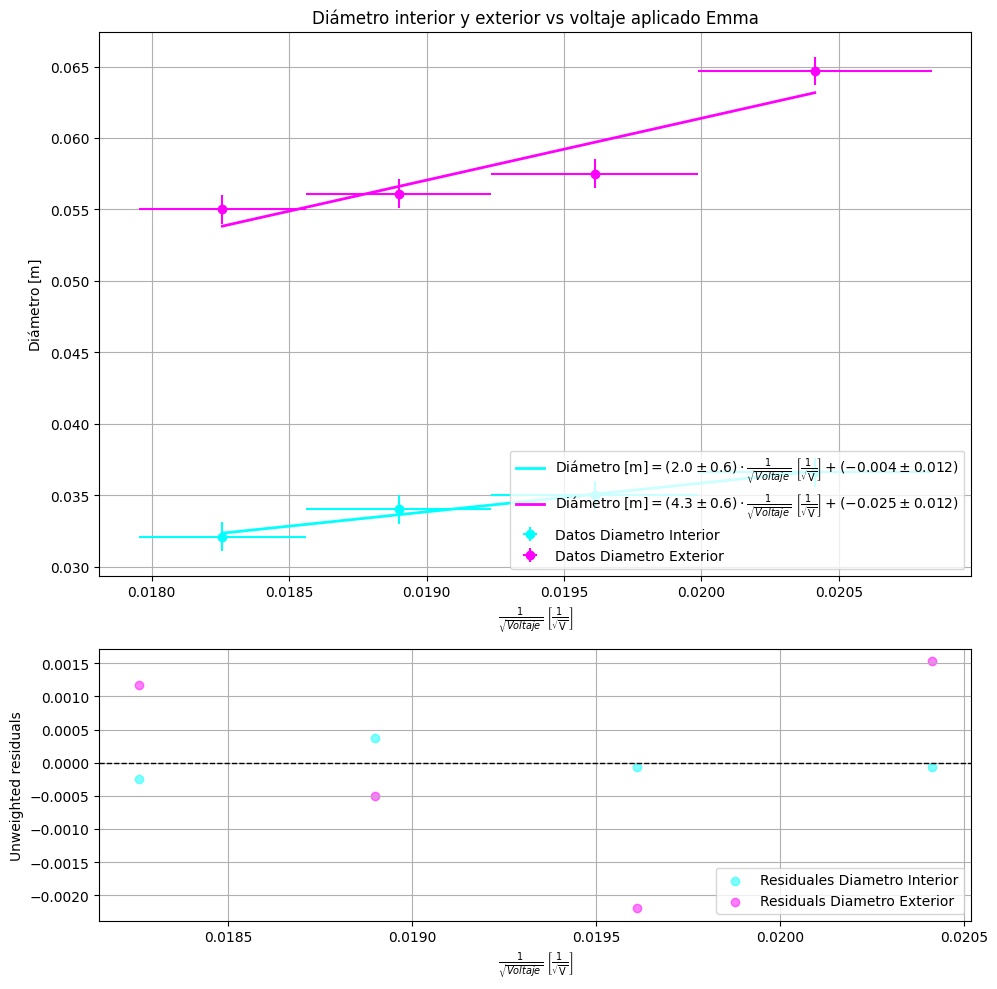

--------------------------------------------------------------------------- 


VALORES EXPERIMENTALES CTES
d1 = (165.56750531866217 +/- 49.67025159559865) pm
Incertidumbre relativa de 30.0%
Z-score de 0.9549477435210111


d2 = (77.00814200868007 +/- 10.745322140746056) pm
Incertidumbre relativa de 13.953488372093023%
Z-score de 4.280174888095694


h = (8.524335371446329e-34 +/- 2.5573006114338985e-34) Js
Incertidumbre relativa de 30.0%
Z-score de 0.742292561523284


h = (1.058338257736611e-33 +/- 1.4767510573068988e-34) Js
Incertidumbre relativa de 13.953488372093023%
Z-score de 2.679742403288288




In [ ]:
#Datos Emma
U= np.array([2.4,2.6,2.8,3]) #kV
err_U=np.array([0.1]*4) #Incertidumbre +-0.1 kV

Dg= np.array([6.47, 5.75, 5.61, 5.50]) #Diámetro grande cm
Dp= np.array([3.66, 3.50, 3.40, 3.21]) #Diámetro pequeño cm
err_D= np.array([0.1]*4) #incertidumbre diametros +-0.1 cm


#---------------------------------------------------------------------------------------------------
#TABLA:
d1= 213e-12 #m
d2= 123e-12 #m
brog,err_brog = broglie(U*1000, err_U*1000) #m
brag1, err_brag1 = bragg(d1,Dp/100,err_D/100) #m
brag2, err_brag2 = bragg(d2,Dg/100,err_D/100) #m


tabla1 = {
    "V (kV)": U, #err +-0.1 kV
    "D1 (cm)": Dp, #err +-0.1 cm
    "D2 (cm)": Dg, #err +-0.1 cm
    "λ_broglie (pm)": brog * 1e12,
    "sigma_λ_broglie (pm)": err_brog * 1e12,
    "λ¹_bragg (pm)": brag1 * 1e12,
    "sigma_λ¹_bragg (pm)": err_brag1 * 1e12,
    "λ²_bragg (pm)": brag2 * 1e12,
    "sigma_λ²_bragg (pm)": err_brag2 * 1e12
}

df = pd.DataFrame(tabla1)
print("TABLA RESULTADOS")
print(df)
print("--------------------------------------------------------------------------- \n\n")



#---------------------------------------------------------------------------------------------------
#Grafica
x = 1/np.sqrt(U*1000) # unidades 1/sqrt(V)
err_x = (err_U*1000)/ (2*(U*1000)**1.5) # unidades 1/sqrt(V)
y1= Dp/100 #m
y2= Dg/100 #m
err_y= err_D/100 #m

data1 = {"x": x, "y": y1, "err_x": err_x, "err_y": err_y}
data2 = {"x": x, "y": y2, "err_x": err_x, "err_y": err_y}

labels = {
    "x": r"\frac{1}{\sqrt{Voltaje}} \; \left[ \frac{1}{\sqrt{\text{V}}} \right]",
    "y": r"\text{Diámetro} \; [\text{m}]",
    "title": 'Diámetro interior y exterior vs voltaje aplicado Emma'}
print("DATOS GRAFICA")
graph_diameters(data1, data2, labels, save_graph=False)
print("--------------------------------------------------------------------------- \n\n")



#---------------------------------------------------------------------------------------------------
#Valores Constantes
pendiente_g= 4.3
err_pend_g = 0.6
pendiente_p= 2.0
err_pend_p = 0.6

dist1, err_dist1 = distancia(pendiente_p,err_pend_p)
dist2, err_dist2 = distancia(pendiente_g,err_pend_g)
cte_plank1, error_cte_plank1= plank(pendiente_p,err_pend_p,d1)
cte_plank2, error_cte_plank2= plank(pendiente_g,err_pend_g,d2)

print("VALORES EXPERIMENTALES CTES")
h= 6.62607015e-34 #J s
print(f"d1 = ({dist1*1e12} +/- {err_dist1*1e12}) pm")
incertidumbre_relativa(dist1*1e12,err_dist1*1e12)
z_score(213,dist1*1e12,err_dist1*1e12)
print("\n")

print(f"d2 = ({dist2*1e12} +/- {err_dist2*1e12}) pm")
incertidumbre_relativa(dist2*1e12,err_dist2*1e12)
z_score(123,dist2*1e12,err_dist2*1e12)
print("\n")
print(f"h = ({cte_plank1} +/- {error_cte_plank1}) Js")
incertidumbre_relativa(cte_plank1,error_cte_plank1)
z_score(h,cte_plank1,error_cte_plank1)
print("\n")
print(f"h = ({cte_plank2} +/- {error_cte_plank2}) Js")
incertidumbre_relativa(cte_plank2,error_cte_plank2)
z_score(h,cte_plank2,error_cte_plank2)
print("\n")

Pendientes Esperadas

In [ ]:
d1= 213e-12 #m
d2= 123e-12 #m
h= 6.62607015e-34 #J s
e=1.602176634e-19 # C
m_e= 9.1093837139e-31 #kg
L=0.135

print((2*L*h)/(d1*np.sqrt(2*e*m_e)))
print((2*L*h)/(d2*np.sqrt(2*e*m_e)))

1.5546244630860295
2.692154558027027
